In [14]:
%autosave 60
%matplotlib inline
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd

from lmfit.models import VoigtModel, ConstantModel, LinearModel, GaussianModel, LorentzianModel
from nexusformat.nexus import nxload
from pathlib import Path

import datetime
import csv

import os

from PyMca5.PyMcaIO import specfilewrapper
from matplotlib import dates
from datetime import datetime
from scipy import integrate
from scipy.signal import convolve
from lmfit import minimize, Parameters, Parameter, report_fit 
from lmfit.models import  ConstantModel, VoigtModel, Pearson7Model,GaussianModel, LorentzianModel, LinearModel, ExpressionModel,PolynomialModel,ExponentialModel,StepModel,RectangleModel,LinearModel, QuadraticModel, DampedOscillatorModel
from scipy.interpolate import interp1d



class Load_file():
    
    def __init__(self,path):
        self.path = path
        nexus = nxload(self.path)
        self._get_attributes_(nexus)
        
    def _get_attributes_(self, nexus):
        #Get attributes from nexus file #
        try:
            self.TEY = nexus['entry']['instrument']['fesData']['tey'].nxvalue #tey #C1
            self.TFY = nexus['entry']['instrument']['fesData']['d90'].nxvalue #d90 #C5
            self.I0 = nexus['entry']['instrument']['fesData']['i0'].nxvalue #I0 C2
        except:
            self.TEY = nexus['entry']['instrument']['fesData']['C1'].nxvalue #tey #C1
            self.TFY = nexus['entry']['instrument']['fesData']['C5'].nxvalue #d90 #C5
            self.I0 = nexus['entry']['instrument']['fesData']['C2'].nxvalue #I0 C2
        self.Field = nexus['entry']['instrument']['scm']['field_z'].nxvalue
        self.T_sample = nexus['entry']['instrument']['scm']['T_sample'].nxvalue
        self.polarisation = nexus['entry']['instrument']['id']['polarisation'].nxvalue
        self.energy = nexus['entry']['instrument']['fastEnergy']['value'].nxvalue
        
        self.number = str(self.path).split('/')[-1].split('.')[0].split('-')[-1]


class Spectra_data:
    def __init__(self,filename,scannumber):
        self.filename = filename
        self.scannumber = scannumber
        self.data, self.metadata = self._Read_in(self.filename,self.scannumber)

        self._get_important_data()

    def _get_important_data(self):
            self.energy = self.data["energy_mono_ct"]
            self.TEY = self.data["adc2_i3"]
            self.I0 = self.data["adc2_i2"]
            
            self.TEY = self.TEY
            
            self.Field = float(self.metadata["magnet_y"])
            self.T_sample = float(self.metadata["xmcd_temp_1K"])
            self.Angle = float(self.metadata["xmcd_rotation"])
            self.polarisation = float(self.metadata["ideu71_motor_phase"])
            self.number = self.scannumber.split('.')[0]
            if self.polarisation > 0:
                self.polarisation = "pc"
            elif self.polarisation < 0:
                self.polarisation = "nc"
            else:
                return Exception("Polarisation value not recognised -> check ideu71_motor_phase")
            return 1
    
    def _Read_in(self,filename,scannumber):   
        """
        General function that reads in all the data for one spectra
        Parameters
        ----------
        filename : Str
            Name of file spectra have been saved in
        scannumber : Str
            Number of scan usualy in form 6.2 ectt.

        Returns 2 Dictionaries containing all scan data and all metadata
        -------
        None.
        """
        # Reading in the file
        sf = specfilewrapper.Specfile(filename)
        try:
            scan = sf.select(scannumber)
        except:
            raise Exception(f"No Scannumber: {scannumber}")
        labels = scan.alllabels()  
        Metadata_labels = scan.header("O")
        Metadata_data = scan.header("P")
        
        data = []
        labels1 = np.array([])
        data1 = np.array([])
        # Recorded data
        for i in range(1,len(labels)+1):
            arr = scan.datacol(i)
            data.append(arr)
        
        # Metadata
        for i in range(0,19):
            arr = Metadata_labels[i].split() 
            arr1 = Metadata_data[i].split()
            arr = [item.strip() for item in arr]  
            arr1 = [item.strip() for item in arr1]  
            labels1 = np.append(labels1,arr)
            data1 = np.append(data1,arr1)
        
        # Saving it all together in 2 dictionarys
        Metadata_dictionary = dict(zip(labels1,data1))
        Data_dictionary = dict(zip(labels,data))
        return Data_dictionary,Metadata_dictionary

print("All good")

Autosaving every 60 seconds
All good


In [2]:
class fitted_peaks():

    def __init__(self, file, energies):
        self.file = file
        self.energies = energies
        self.normalised = False
        print(self.energies)
        self.plot_fit()
        self.print_results()

    def fit_global(self, centers=None, ):

        self.normalise_XAS(True)
        x = self.file.energy
        y = self.normalised_XAS

        # model = ConstantModel(prefix='bkg_')
        # params = model.make_params(c=0.0)
        # params['bkg_c'].set(value=0.0, min=-0.01, max=0.01)

        ## Background of fit, just tries a linear background around 0

        model = LinearModel(prefix='bkg_')
        params = model.make_params(slope=0.0, intercept=0.0)
        params['bkg_slope'].set(value=0.0, min=-0.02, max=0.02)
        params['bkg_intercept'].set(value=0.0, min=-0.05, max=0.01)

        if centers is None:
            self.centers = [575.4,576.5,577.2, 579]
        else:
            self.centers = centers
        amp_guess = max((np.max(y) - np.min(y)) / 5, 1e-3)

        for i, c in enumerate(self.centers, start=1):
            prefix = f'v{i}_'
            ### Make a peak for each of the list of energies youve given it
            peak = VoigtModel(prefix=prefix)
            # peak = LorentzianModel(prefix=prefix)
            # peak = GaussianModel(prefix=prefix)
            ### add the peak to the background 
            model += peak

            p = peak.make_params()
            p[prefix + 'center'].set(value=c, min=c - 1, max=c + 1)
            p[prefix + 'sigma'].set(value=0.25, min=0.02, max=2.0)
            # p[prefix + 'gamma'].set(value=0.25, min=0.02, max=2.0)
            p[prefix + 'amplitude'].set(value=amp_guess, min=0.0)
            params.update(p)

        self.result = model.fit(y, params, x=x)
        self.x_fit = x
        self.y_fit = y
        self.components = self.result.eval_components(x=x)
    


    def plot_fit(self):
        self.fit_global(self.energies)

        fig, (fit_ax, residuals_ax) = plt.subplots(
            2, 1, figsize=(8, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex=True
        )

        # data + total fit
        fit_ax.plot(self.file.energy, self.normalised_XAS, ms=3, label='Normalised XAS')
        num_peaks = len(self.centers)
        fit_ax.plot(self.x_fit, self.result.best_fit, 'r-', lw=2, label=f'Total fit')

        # each Voigt component
        for i in range(1, num_peaks + 1):
            key = f'v{i}_'
            fit_ax.plot(self.x_fit, self.components[key], '--', lw=1.3, label=f'Voigt {i}')

        # background component
        fit_ax.plot(self.x_fit, self.components['bkg_'], ':', lw=1.5, label='Background')

        fit_ax.set_ylabel('Normalised XAS (a.u.)')
        fit_ax.set_title('Fit to XAS: ' + self.file.number)
        for center in self.centers:
            fit_ax.axvline(center, color='gray', ls='--', lw=0.8)
        fit_ax.legend()

        # residuals
        resid = self.y_fit - self.result.best_fit
        residuals_ax.plot(self.x_fit, resid, 'b-', lw=1)
        residuals_ax.axhline(0, color='k', ls='--', lw=1)
        residuals_ax.axhline(max(resid), color='r', ls='--', lw=0.8, label='Max = {:.3f}'.format(max(resid)))
        residuals_ax.axhline(min(resid), color='r', ls='--', lw=0.8, label='Min = {:.3f}'.format(min(resid)))
        for center in self.centers:
            residuals_ax.axvline(center, color='gray', ls='--', lw=0.8)
        residuals_ax.legend()
        residuals_ax.set_xlabel('Energy (eV)')
        residuals_ax.set_ylabel('Residual')

        plt.tight_layout()
        plt.show()
        
        

    def print_results(self):
        p = self.result.params
        rows = []

        for i in range(1, len(self.centers) + 1):
            pre = f"v{i}_"
            rows.append({
                "peak": i,
                "center": p[pre + "center"].value,
                "amplitude": p[pre + "amplitude"].value,      # Voigt area parameter
                "amplitude_err": p[pre + "amplitude"].stderr,
                "fwhm": p[pre + "fwhm"].value,                # derived by lmfit
                "fwhm_err": p[pre + "fwhm"].stderr,
                "height": p[pre + "height"].value,            # peak maximum
                "height_err": p[pre + "height"].stderr,
            })

        peaks_df = pd.DataFrame(rows)
        print(f"Fit results for file: {self.file.number}")
        print("Polarisation: ",self.file.polarisation, self.file.Field, self.file.T_sample)
        print(peaks_df)

    def normalise_XAS(self, mask=False):
        if self.normalised:
            print("Already normalised")
            return
        self.normalised_XAS = self.file.TEY / self.file.I0

        self.normalised_XAS -= np.mean(self.normalised_XAS[0:30]) 
        self.normalised_XAS /= np.max(self.normalised_XAS)
        self.normalised = True

        if mask:
            mask_range = (self.file.energy < 581)
            self.normalised_XAS = self.normalised_XAS[mask_range]
            self.file.energy = self.file.energy[mask_range]

    def plot_normalised_XAS(self):
        self.normalise_XAS()
        
        normalised_XAS_fig, normalised_XAS_ax = plt.subplots()
        normalised_XAS_ax.plot(self.file.energy, self.normalised_XAS, label='Normalised TEY')
        normalised_XAS_ax.set_xlabel('Energy (eV)')
        normalised_XAS_ax.set_ylabel('Normalised Intensity (a.u.)')
        normalised_XAS_ax.set_title('Normalised XAS')
        normalised_XAS_ax.legend()
        plt.show()
    def plot_raw_data(self):
        raw_XAS_fig, raw_XAS_ax = plt.subplots()
        raw_XAS_ax.plot(self.file.energy, self.file.TEY, label='TEY')
        raw_XAS_ax.set_xlabel('Energy (eV)')
        raw_XAS_ax.set_ylabel('Intensity (a.u.)')
        raw_XAS_ax.set_title('Raw Data')
        raw_XAS_ax.legend()
        plt.show()

    
        



['C:\\Users\\ppxfc1\\OneDrive - The University of Nottingham\\Desktop\\PhD\\Code\\PhD-Codes\\Analysis code\\CrCl3_XMCD_feb26\\XAS\\i06-1-348423.nxs', 'C:\\Users\\ppxfc1\\OneDrive - The University of Nottingham\\Desktop\\PhD\\Code\\PhD-Codes\\Analysis code\\CrCl3_XMCD_feb26\\XAS\\i06-1-348424.nxs', 'C:\\Users\\ppxfc1\\OneDrive - The University of Nottingham\\Desktop\\PhD\\Code\\PhD-Codes\\Analysis code\\CrCl3_XMCD_feb26\\XAS\\i06-1-382520.nxs', 'C:\\Users\\ppxfc1\\OneDrive - The University of Nottingham\\Desktop\\PhD\\Code\\PhD-Codes\\Analysis code\\CrCl3_XMCD_feb26\\XAS\\i06-1-382521.nxs']
0.0
1.0
0.0


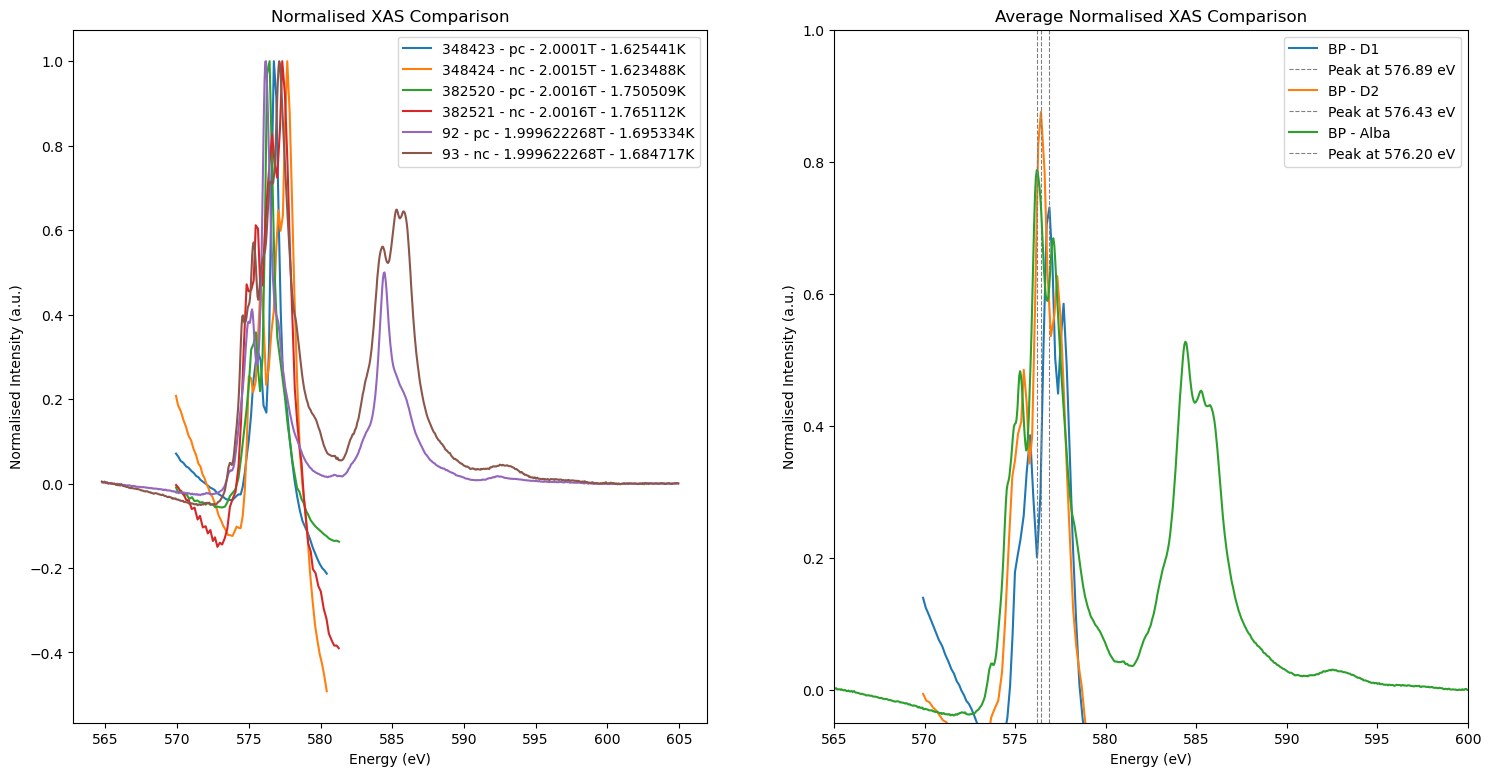

In [51]:
### Plot all 

class plot_files():

    def __init__(self, files,labels = None,  scan_numbers=None, both = False):

        self.XAS_fig, [self.XAS_ax, self.XAS_avg_ax] = plt.subplots(1,2, figsize=(18, 9)) 
        self.both = both
        self.labels = labels if labels else ["HOPG", "BP", "NbSe2", "Au"]
        self.plot_all(files, scan_numbers=scan_numbers)


    def plot_all(self, files, scan_numbers=None):
        if files[0].endswith('.nxs'):
            self.process_diamond(files)
        elif files[0].endswith('.dat'):
            self.process_spec(files, scan_numbers)

        if self.both:
            self.process_spec([r"C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Alba\data01_10Dec2025.dat"], scan_numbers)
            


        
        self.XAS_ax.set_xlabel('Energy (eV)')
        self.XAS_ax.set_ylabel('Normalised Intensity (a.u.)')
        self.XAS_ax.set_title('Normalised XAS Comparison')
        self.XAS_ax.legend()
        self.XAS_avg_ax.set_xlabel('Energy (eV)')
        self.XAS_avg_ax.set_ylabel('Normalised Intensity (a.u.)')
        self.XAS_avg_ax.set_title('Average Normalised XAS Comparison')
        self.XAS_avg_ax.set_xlim(565, 600)
        self.XAS_avg_ax.set_ylim(-0.05, 1)
        self.XAS_avg_ax.legend()
        plt.show()
    def process_diamond(self, files):

         for i, path in enumerate(files):
            if i%2 == 0:
                XAS = 0
            if path.endswith('.nxs'):
                self.file = Load_file(path)
            else:
                raise ValueError(f"Unsupported file format: {path}")
            
            self.normalise_XAS()
            XAS += self.normalised_XAS
            if i%2 == 1:
                print((i+1)/2 - 1)
                self.XAS_avg_ax.plot(self.file.energy, XAS/2, label=f'{self.labels[int((i+1)/2 - 1)]}')
                self.XAS_avg_ax.axvline(self.file.energy[np.argmax(XAS/2)],label =f'Peak at {self.file.energy[np.argmax(XAS/2)]:.2f} eV', color='gray', ls='--', lw=0.8)
            self.XAS_ax.plot(self.file.energy, self.normalised_XAS, label=f'{self.file.number} - {self.file.polarisation} - {self.file.Field}T - {self.file.T_sample}K')

    def process_spec(self, files, scan_numbers=None):
         
         for i, SN in enumerate(scan_numbers):
            if i%2 == 0:
                XAS = 0
            if files[0].endswith('.dat'):
                self.file = Spectra_data(files[0], scan_numbers[i])
            else:
                raise ValueError(f"Unsupported file format: {files[0]}")
            
            self.normalise_XAS()
            XAS += self.normalised_XAS
            if i%2 == 1:
                print((i+1)/2 - 1)
                if self.both:
                    label = f'BP - Alba'
                else: 
                    label = f'{self.labels[int((i+1)/2 - 1)]}'
                self.XAS_avg_ax.plot(self.file.energy, XAS/2, label=label)
                self.XAS_avg_ax.axvline(self.file.energy[np.argmax(XAS/2)], label =f'Peak at {self.file.energy[np.argmax(XAS/2)]:.2f} eV', color='gray', ls='--', lw=0.8)
            self.XAS_ax.plot(self.file.energy, self.normalised_XAS, label=f'{self.file.number} - {self.file.polarisation} - {self.file.Field}T - {self.file.T_sample}K')
            
        
    def normalise_XAS(self, mask=False, subtract_linear_bkg=True):
        
        self.normalised_XAS = self.file.TEY / self.file.I0

        # Subtract linear background fitted to start and end points
        if subtract_linear_bkg:
            n_start = 30  # number of points at beginning
            n_end = 30    # number of points at end
            
            # Combine start and end regions
            x_bkg = np.concatenate([self.file.energy[:n_start], self.file.energy[-n_end:]])
            y_bkg = np.concatenate([self.normalised_XAS[:n_start], self.normalised_XAS[-n_end:]])
            
            # Fit linear background: y = mx + c
            coeffs = np.polyfit(x_bkg, y_bkg, 1)
            linear_bkg = np.polyval(coeffs, self.file.energy)
            
            # Subtract background
            self.normalised_XAS -= linear_bkg

        self.normalised_XAS -= np.mean(self.normalised_XAS[0:30]) 
        self.normalised_XAS /= np.max(self.normalised_XAS)
        

        if mask:
            mask_range = (self.file.energy < 581)
            self.normalised_XAS = self.normalised_XAS[mask_range]
            self.file.energy = self.file.energy[mask_range]



data_dir = r"C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\XAS"
files = [data_dir+"\\"+f for f in os.listdir(data_dir) if f.endswith('.nxs') or f.endswith('.dat')]
print(files)
# files = [r"C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Alba\data01_10Dec2025.dat"]
plot_files(files,["BP - D1", "BP - D2 "], ["92", "93"], both=True)



[574.8, 575.55, 576.5, 577.2, 579]


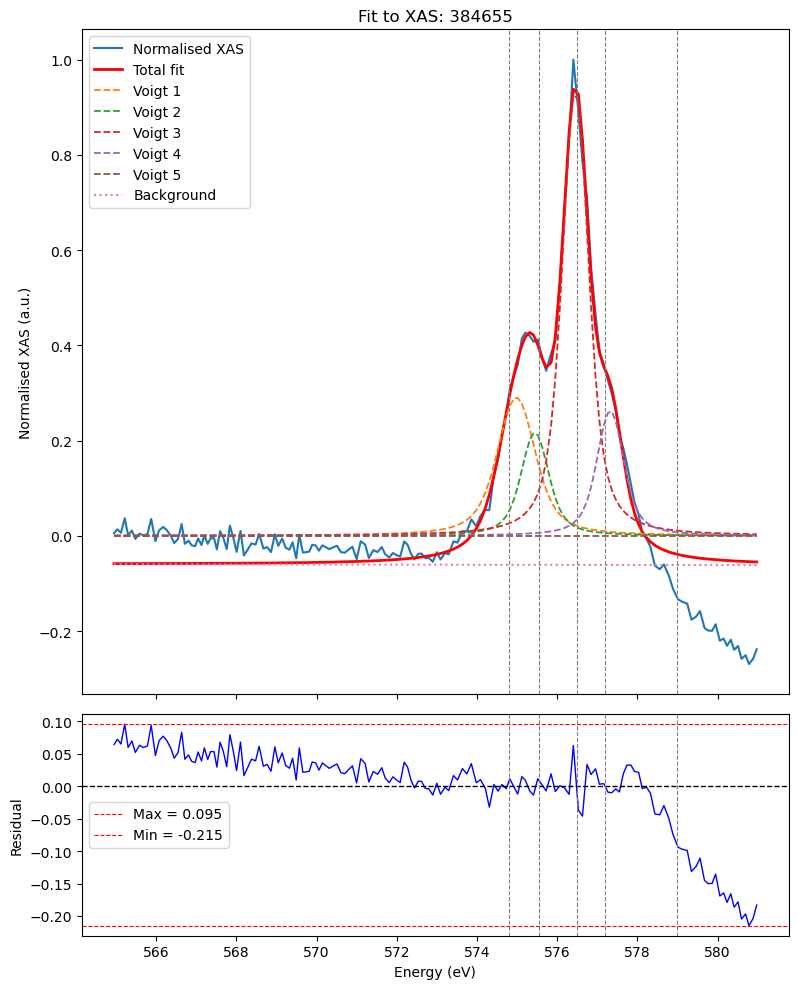

Fit results for file: 384655
Polarisation:  pc 2.0016 2.244859
   peak      center     amplitude amplitude_err      fwhm fwhm_err  \
0     1  574.980091  4.389886e-01          None  1.136173     None   
1     2  575.444343  2.379386e-01          None  0.825880     None   
2     3  576.456784  9.901535e-01          None  0.792580     None   
3     4  577.324638  2.805587e-01          None  0.803389     None   
4     5  578.600986  1.561196e-12          None  0.905100     None   

         height height_err  
0  2.904081e-01       None  
1  2.165448e-01       None  
2  9.389865e-01       None  
3  2.624810e-01       None  
4  1.296465e-12       None  


In [4]:
def total_fit_code(path, scan_number="99"):
    # Detect file type and use appropriate loader
    if path.endswith('.nxs'):
        file = Load_file(path)
        energies = [574.8,575.55,576.5,577.2, 579]
    elif path.endswith('.dat'):
        file = Spectra_data(path, scan_number)
        energies = [574.8,575.55,576.5,577.2, 579]
    else:
        raise ValueError(f"Unsupported file format: {path}")
    
    peak = fitted_peaks(file, energies)

# total_fit_code(r'C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Alba\data01_10Dec2025.dat')

# total_fit_code(r'C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Diamond_25\i06-1-347233.nxs')
# total_fit_code(r'C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Diamond_26\HOPG\i06-1-382273.nxs')
total_fit_code(r'C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Diamond_26\Au\i06-1-384655.nxs')
# total_fit_code(r'C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\i06-1-382628.nxs')
